# Poultry–Pork Supply Divergence → U.S. Beef Processing (NAICS 311611)

**Status:** REPRODUCED RETROSPECTIVE BEEF PROCESSING MACRO PILOT — **NOT PIT / NOT EQUITY ALPHA**.  
**Target:** U.S. beef physical production YoY log growth six months ahead, **not** Tyson revenue, EPS or total return.  
**Frozen source:** plotnine 0.15.3 redistributed USDA ERS monthly production, 1944-01–2023-12; poultry from 1960-01.  
**OOS:** 2008-01–2023-06; 186 purged expanding-window origins; assumed two-month release buffer; 2026-10-28 execution.


**Notebook execution contract:** all displayed diagnostics below are generated by code from the frozen numerical input, with saved outputs committed alongside this notebook. Source-vintage uncertainty is NOT repaired by execution.

In [1]:
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd
from IPython.display import display, SVG, Markdown
from run_analysis import (HERE, RAW, RESULTS, FIGURES, load_raw, make_panel, walkforward,
    scorecard, rmse, ridge_forecast, _fast_augmented_forecasts, CONTROL, AR,
    LAG, HORIZON, MIN_TRAIN, OOS_START, run_all)
print('Study:', HERE.name, '| frozen raw:', RAW.name)
print('Fixed primary horizon / lag / OOS start:', HORIZON, LAG, OOS_START)

Study: Protein-Substitution-Pressure-to-U.S.-Beef-Processing | frozen raw: raw_plotnine_meat_2023_snapshot.csv
Fixed primary horizon / lag / OOS start: 6 2 2008-01-01


In [2]:
metrics = run_all(draws=1000, bootstrap_draws=2000, weight_draws=1000)
assert metrics['pit_verified'] is False and metrics['equity_alpha_established'] is False
print('Executed 1,000 block reorders, 2,000 paired block bootstraps, 1,000 exposure perturbations')

{
  "raw_n": 960,
  "panel_n": 748,
  "oos_n": 186,
  "observed_rmse_gain_log_pp": -0.02626379920255495,
  "placebo_exploratory_tail_fraction": 0.7522477522477522,
  "bootstrap_gain_ci_95": [
    -0.11520044919967218,
    0.0630903743523934
  ],
  "weight_positive_gain_fraction": 0.0
}
          model  n_oos  rmse_log_pp  mae_log_pp  bias_log_pp
       ar_ridge    186     5.859057    4.372929     0.807760
 supply_control    186     5.872345    4.371908     0.799144
      augmented    186     5.898608    4.396403     1.114625
historical_mean    186     6.072084    4.544264     1.020148
    factor_only    186     6.076099    4.547361     1.009093
    persistence    186     7.592569    5.806400     0.302895
       momentum    186    12.731409    9.434701     0.157800
Executed 1,000 block reorders, 2,000 paired block bootstraps, 1,000 exposure perturbations


## 01. Abstract

**Research question.** Does a two-month-stale poultry-versus-pork production-growth divergence forecast six-month-ahead U.S. beef processing output growth beyond own-industry history and a competing-protein supply control? This is a **falsifiable, retrospective national-volume** study of beef processing (NAICS 311611), distinct from the repository's poultry slaughtering/processing study (NAICS 311615). The source is a frozen, redistributed USDA-origin monthly meat-production dataset; its historical first-release vintages are **UNKNOWN**.

**Primary result.** Across **186** purged expanding-window origins (2008-01 to 2023-06), the factor-augmented model RMSE is **5.8986 log-percentage points** versus **5.8723** for the matched supply-control model: an incremental gain of **-0.0263 log-pp** (negative means deterioration). A 1,000-draw 12-month-block exploratory placebo has upper-tail fraction **0.7522**; the 2,000-draw paired circular-block bootstrap gain interval **[-0.1152, +0.0631]** crosses zero. **Verdict: no stable incremental predictive value; NOT PIT / NOT EQUITY ALPHA.**

In [3]:
display(pd.DataFrame([{'OOS origins':metrics['oos_n'],
 'control RMSE':pd.read_csv(RESULTS/'baseline_scorecard.csv').set_index('model').loc['supply_control','rmse_log_pp'],
 'augmented RMSE':pd.read_csv(RESULTS/'baseline_scorecard.csv').set_index('model').loc['augmented','rmse_log_pp'],
 'gain log-pp':metrics['observed_rmse_gain_log_pp'],
 'PIT verified':metrics['pit_verified']}]))

,OOS origins,control RMSE,augmented RMSE,gain log-pp,PIT verified
0,186,5.872345,5.898608,-0.026264,False


## 02. Research Design & Hypotheses

**H1 — substitution mechanism.** Lagged acceleration in poultry output relative to pork could proxy shifts in retail protein substitution and processing capacity allocation, with uncertain sign for beef output because beef is governed by cattle herd availability and long biological lead times. An alternative mechanism is a common protein demand cycle, which would disappear once beef and pork history is controlled.

**H2 — incremental forecast.** A fixed, nonlinear poultry-minus-pork factor improves six-month-ahead beef YoY output forecasts relative to the same training origins and four lagged own-industry/competing-protein controls.

**H3 — robustness.** Improvement survives 12-month block reordering, block bootstrap, component ablations, broiler/turkey exposure perturbation, alternative lags/horizons, regime splits, and leave-one-OOS-year-out checks.

**Null and failure criterion.** Incremental OOS RMSE gain ≤ 0, bootstrap uncertainty spanning zero, or nonpersistent regime/ablation effects fails the primary thesis. The six-month horizon, 70/30 poultry weights, lag, 2008 OOS start, Ridge penalty and baselines are fixed in code; alternate grids are post-hoc diagnostics, not model selection. This is **not** an ex ante registered investment strategy.

In [4]:
hypotheses = pd.DataFrame([
 ('H1','Poultry-minus-pork volume pressure proxies substitution/capacity; sign ambiguous','Mechanism plausible, not established'),
 ('H2','Factor lowers OOS RMSE vs supply control','Tested on 186 purged OOS origins'),
 ('H3','Gain survives blocks, weights, regimes and ablations','Tested with uncertainty and negative controls')],
 columns=['hypothesis','prediction','evaluation'])
display(hypotheses)

,hypothesis,prediction,evaluation
0,H1,Poultry-minus-pork volume pressure proxies sub...,"Mechanism plausible, not established"
1,H2,Factor lowers OOS RMSE vs supply control,Tested on 186 purged OOS origins
2,H3,"Gain survives blocks, weights, regimes and abl...",Tested with uncertainty and negative controls


In [5]:
print('Fixed choices:', {'lag_months':LAG,'horizon_months':HORIZON,
 'start':OOS_START,'min_train':MIN_TRAIN,'controls':CONTROL,'ridge_alpha':10.0})

Fixed choices: {'lag_months': 2, 'horizon_months': 6, 'start': '2008-01-01', 'min_train': 300, 'controls': ['beef_yoy_lag2', 'beef_yoy_lag8', 'beef_mom3_lag2', 'pork_yoy_lag2'], 'ridge_alpha': 10.0}


## 03. Industry Context

U.S. animal slaughtering and processing includes beef processing under **NAICS 311611**, while the earlier broiler research targets **NAICS 311615**. Beef processing depends on cattle supply, packer capacity, export demand, labor, input costs and margins. In the frozen physical-volume series, 2023 beef production totals **26,964.3 million lb**, versus **27,154.6 million lb** in 2019 (**-0.70%**); this is **not** industry revenue.

The USDA ERS documentation describes the federally inspected `RedMeatPoultry_Prod` compilation and different weight bases for red meat and poultry. We compare **within-series log growth rates**, never aggregate raw pounds across protein categories. Tyson Foods FY2023 SEC filing reports **$19,325 million Beef segment sales** and **−$91 million Beef segment operating income**, demonstrating why physical output does not map mechanically to margins. Tyson's fiscal year ends in September; the national production calendar-year series is not directly aligned to it.

In [6]:
raw=load_raw()
annual=raw.assign(year=raw.date.dt.year).groupby('year')[['beef','pork','broilers','turkey']].sum(min_count=12)
display(annual.loc[[2019,2021,2022,2023]].round(1))

,beef,pork,broilers,turkey
year,,,,
2019,27154.6,27637.5,43905.0,5817.5
2021,27948.2,27674.7,44899.3,5558.4
2022,28290.7,26995.6,46205.8,5222.5
2023,26964.3,27299.6,46383.4,5455.0


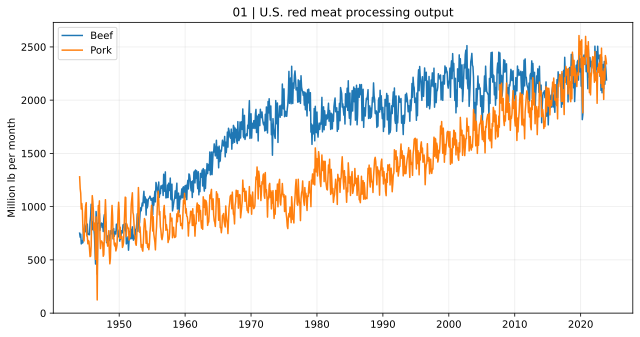

In [7]:
display(SVG(filename=str(FIGURES/'01_red_meat_output.svg')))

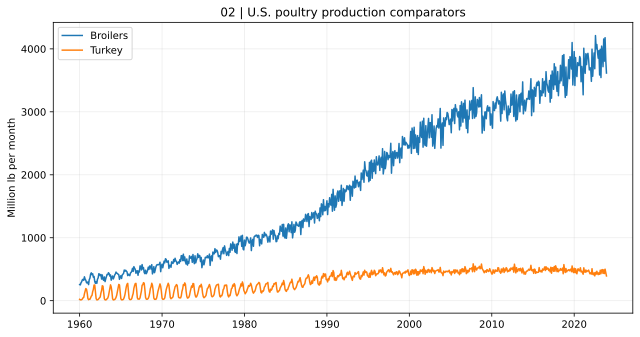

In [8]:
display(SVG(filename=str(FIGURES/'02_poultry_output.svg')))

## 04. Data & Source Integrity

**Frozen empirical input:** `data/raw_plotnine_meat_2023_snapshot.csv`, **960 monthly observations** from 1944-01 to 2023-12, exactly matching the bundled `plotnine 0.15.3` dataset, with SHA-256 `b587c1e758ae43d87fe86fac0efc73da40aaeaf4046eba370f70fced554564a5`. Poultry components begin 1960-01; the fully observed formation panel contains **748** monthly rows. No missing production is imputed. QA checks schema, continuity, duplicates, positive quantities and nonmissing formation variables.

`data/source_register.csv` has **Grade A** USDA/SEC original documentation and filing, and **Grade B** the frozen redistributed numerical series. There is **no Grade A historical numerical-vintage panel**; the official USDA current page is NOT the vintage of the frozen file. The 2023 SEC filing supplies a **separate, dated** nine-row FY2021–FY2023 Tyson segment-fundamentals table, not an OOS issuer forecast panel. No Grade C source is used numerically. Original publication dates for the bundled monthly observations are **UNKNOWN**; the dataset's bundled assembly date is also **UNKNOWN**.

In [9]:
sources=pd.read_csv(HERE/'data/source_register.csv')
display(sources[['id','grade','publisher','release_date','observation_start','observation_end','publication_lag']])

,id,grade,publisher,release_date,observation_start,observation_end,publication_lag
0,S01,B,plotnine project,UNKNOWN (bundled snapshot not dated),1944-01,2023-12,UNKNOWN historical original releases
1,S02,A,USDA Economic Research Service,UNKNOWN (documentation undated),1921 (documentation history),ongoing,UNKNOWN for each historical vintage
2,S03,A,USDA Economic Research Service,2026-10-27 (page updated),historical,ongoing,Monthly updates; individual release timestamps...
3,S04,A,U.S. Securities and Exchange Commission,2023-11-13,2021 fiscal year,2023 fiscal year,2023-11-13 filing availability


In [10]:
raw_hash=hashlib.sha256(RAW.read_bytes()).hexdigest()
assert raw_hash==metrics['raw_sha256']
print('Frozen raw SHA256:',raw_hash)
print('Rows:',len(raw),'Date continuity:',raw.date.is_unique,
 'Broiler observations:',raw.broilers.notna().sum(),
 'Turkey observations:',raw.turkey.notna().sum())

Frozen raw SHA256: b587c1e758ae43d87fe86fac0efc73da40aaeaf4046eba370f70fced554564a5
Rows: 960 Date continuity: True Broiler observations: 768 Turkey observations: 768


In [11]:
display(raw.iloc[[0,1,191,192,-2,-1]][['date','beef','pork','broilers','turkey']])

,date,beef,pork,broilers,turkey
0,1944-01-01,751.0,1280.0,NaN,NaN
1,1944-02-01,713.0,1169.0,NaN,NaN
191,1959-12-01,1160.0,1125.0,NaN,NaN
192,1960-01-01,1196.0,1058.0,255.9,22.1
958,2023-11-01,2280.9,2388.2,3817.3,449.2
959,2023-12-01,2189.9,2342.0,3615.6,393.0


## 05. Point-in-Time Availability

At forecast formation month *t*, every model input is observed no later than **t−2 months**. This is a conservative **assumed** publication buffer, not verified historical release metadata. For a training origin *s* with horizon *h=6*, its label is permitted only when **s+6+2 ≤ t**, i.e. *s ≤ t−8*. The expanding window includes only labels available by the origin; all standardization and Ridge coefficients are fit on each training fold, never on the full dataset.

The actual training set spans **555–740** rows per forecast. Because the fixed plotnine file may incorporate revisions made after each historical formation month, even this purge cannot prove true **point-in-time** validity. No feature's historical initial publication date has been independently archived and matched. Any apparent gain is retrospective association only.

In [12]:
panel=make_panel(raw)
assert (panel.label_available>panel.target_date).all()
display(panel[['date','target_date','label_available','beef_yoy_lag2','factor','target']].iloc[[0,1,-2,-1]])

,date,target_date,label_available,beef_yoy_lag2,factor,target
0,1961-03-01,1961-09-01,1961-11-01,3.208831,0.943639,-2.417272
1,1961-04-01,1961-10-01,1961-12-01,-0.275862,0.736120,5.619023
746,2023-05-01,2023-11-01,2024-01-01,-4.150041,-0.138791,-6.002354
747,2023-06-01,2023-12-01,2024-02-01,-11.719224,0.197054,-1.617066


In [13]:
pred=walkforward(panel)
assert (pred.max_training_label_available<=pred.date).all()
print('OOS:',pred.date.min().date(),pred.date.max().date(),'N:',len(pred))
print('Train min/max:',pred.n_train.min(),pred.n_train.max())
display(pred[['date','max_training_target_date','max_training_label_available','n_train']].iloc[[0,-1]])

OOS: 2008-01-01 2023-06-01 N: 186
Train min/max: 555 740


,date,max_training_target_date,max_training_label_available,n_train
0,2008-01-01,2007-11-01,2008-01-01,555
185,2023-06-01,2023-04-01,2023-06-01,740


## 06. Factor Construction

Let \(Q_{j,t}\) be USDA-origin physical monthly output for category \(j\), in million lb, and define \(g_{j,t}=100\log(Q_{j,t}/Q_{j,t-12})\) in log-percentage points. At formation month \(t\) with assumed two-month publication buffer, the fixed candidate is

\[F_t=\tanh\!\left(\frac{0.7g_{broiler,t-2}+0.3g_{turkey,t-2}-g_{pork,t-2}}{20}\right).\]

The target is \(Y_t=g_{beef,t+6}\), six-month-ahead **beef production YoY growth**, not beef price, company sales, EPS or shareholder total return. No beef outcome enters the candidate factor. The 70/30 and divisor 20 are prespecified descriptive scale choices; exposure-weight sensitivity is reported separately and not used to pick a favorable weight. Factor sign is economically ambiguous and must be tested rather than assumed.

In [14]:
fcheck=np.tanh((.7*panel.broiler_yoy_lag2+.3*panel.turkey_yoy_lag2-panel.pork_yoy_lag2)/20.)
assert np.allclose(fcheck,panel.factor)
display(panel[['factor_raw','factor','target']].describe().round(4))

,factor_raw,factor,target
count,748.0000,748.0000,748.0000
mean,2.4113,0.0956,0.9614
std,8.8686,0.3612,6.0875
min,-25.3854,-0.8536,-22.1427
25%,-3.1141,-0.1545,-2.4358
50%,1.6266,0.0812,1.0643
75%,7.2998,0.3496,4.9196
max,35.7415,0.9455,25.6468


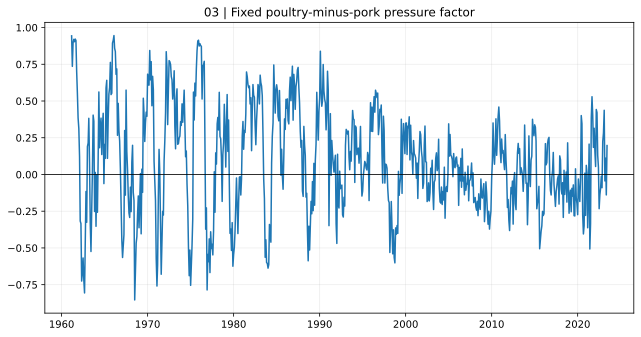

In [15]:
display(SVG(filename=str(FIGURES/'03_factor_history.svg')))

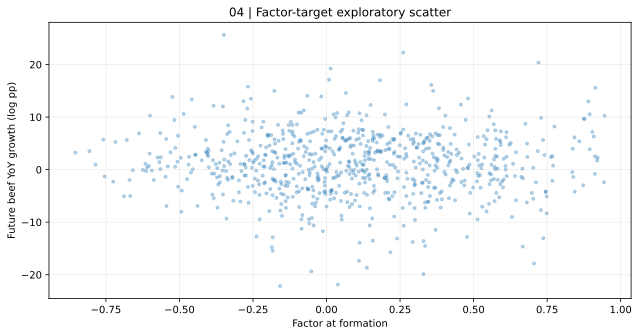

In [16]:
display(SVG(filename=str(FIGURES/'04_scatter.svg')))

In [17]:
print('Exploratory full-panel Spearman, NOT stock IC:',
 round(panel[['factor','target']].corr(method='spearman').iloc[0,1],6))

Exploratory full-panel Spearman, NOT stock IC: 0.000239


## 07. Exposure & Transmission

The company mapping is **dated and descriptive**, not a fitted security panel. The SEC-filed Tyson FY2023 Form 10-K (filed 2023-11-13) distinguishes Beef ($19,325m sales), Pork ($5,768m) and Chicken ($17,060m) segments. These are issuer-specific FY2023 accounting categories, not U.S. national production shares, and **must not** be backdated to 2008–2022. See `data/company_exposure_map.csv` and `data/tyson_fy2023_sec_fundamentals.csv`.

**Transmission chain:** poultry/pork output divergence → hypothesized substitution/packer allocation → later national beef production → potentially issuer volumes, pricing and operating margins → **unmeasured** stock returns. Every arrow beyond national beef production is a hypothesis. The FY2021–FY2023 Tyson segment fundamentals are displayed as a small descriptive cross-check only; there is **no credible issuer-level OOS validation** and leave-one-company-out is **not estimable** with one mapped issuer.

In [18]:
exposure=pd.read_csv(HERE/'data/company_exposure_map.csv')
display(exposure[['company','segment','fiscal_year','filing_date','observed_sales_usd_millions','model_weight']])

,company,segment,fiscal_year,filing_date,observed_sales_usd_millions,model_weight
0,Tyson Foods,Beef,2023,2023-11-13,19325,NOT USED
1,Tyson Foods,Pork,2023,2023-11-13,5768,NOT USED
2,Tyson Foods,Chicken,2023,2023-11-13,17060,NOT USED


In [19]:
firm=pd.read_csv(HERE/'data/tyson_fy2023_sec_fundamentals.csv')
display(firm.pivot(index='fiscal_year',columns='segment',values='sales_usd_millions'))
display(firm.pivot(index='fiscal_year',columns='segment',values='operating_income_usd_millions'))

segment,Beef,Chicken,Pork
fiscal_year,,,
2021,17999,13733,6277
2022,19854,16961,6414
2023,19325,17060,5768


segment,Beef,Chicken,Pork
fiscal_year,,,
2021,3240,-625,328
2022,2502,955,193
2023,-91,-770,-139


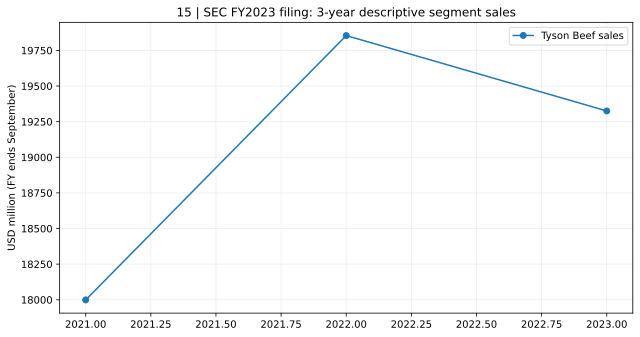

In [20]:
display(SVG(filename=str(FIGURES/'15_tyson_fundamentals.svg')))

## 08. Outcomes & Baselines

All models forecast the same beef-production target at exactly the same formation dates. **Historical mean** uses training labels only. **Persistence** uses two-month-stale beef YoY growth; **momentum** extrapolates the difference between stale beef YoY and its six-month-older value. **AR Ridge** uses three stale beef lags; **supply control** adds stale pork YoY; **factor only** uses just the candidate; **augmented** adds the factor to the supply control.

Ridge minimizes \(\sum_{s\in train}(Y_s-a-X_s\beta)^2+10\lVert\beta\rVert_2^2\) after **train-fold-only** centering and standardization, with unpenalized intercept. No full-sample scaling, target-dependent feature selection or hyperparameter optimization. The primary metric is OOS RMSE in log-pp; MAE and forecast bias are supplementary. There is no equity cross-section, so stock IC, top-minus-bottom return spreads, transaction costs and benchmark-adjusted total returns are **NOT COMPUTABLE**.

In [21]:
scores=scorecard(pred)
display(scores.round(4))

,model,n_oos,rmse_log_pp,mae_log_pp,bias_log_pp
3,ar_ridge,186,5.8591,4.3729,0.8078
4,supply_control,186,5.8723,4.3719,0.7991
6,augmented,186,5.8986,4.3964,1.1146
0,historical_mean,186,6.0721,4.5443,1.0201
5,factor_only,186,6.0761,4.5474,1.0091
1,persistence,186,7.5926,5.8064,0.3029
2,momentum,186,12.7314,9.4347,0.1578


In [22]:
assert np.max(np.abs(_fast_augmented_forecasts(panel)-pred.augmented.to_numpy()))<1e-8
print('Fast cumulative Ridge agrees with independent fold-by-fold implementation to < 1e-8')
print('All models share',len(pred),'identical target dates and training cutoff rule')

Fast cumulative Ridge agrees with independent fold-by-fold implementation to < 1e-8
All models share 186 identical target dates and training cutoff rule


## 09. Empirical Findings

**Primary scorecard (lower RMSE better; identical 186 OOS origins):**

| model           |   n_oos |   rmse_log_pp |   mae_log_pp |   bias_log_pp |
|:----------------|--------:|--------------:|-------------:|--------------:|
| ar_ridge        |     186 |        5.8591 |       4.3729 |        0.8078 |
| supply_control  |     186 |        5.8723 |       4.3719 |        0.7991 |
| augmented       |     186 |        5.8986 |       4.3964 |        1.1146 |
| historical_mean |     186 |        6.0721 |       4.5443 |        1.0201 |
| factor_only     |     186 |        6.0761 |       4.5474 |        1.0091 |
| persistence     |     186 |        7.5926 |       5.8064 |        0.3029 |
| momentum        |     186 |       12.7314 |       9.4347 |        0.1578 |

The factor increases RMSE by **0.0263 log-pp** relative to supply controls; the AR Ridge baseline (**5.8591**) also beats the augmented model (**5.8986**). Full-panel factor-versus-future-beef-growth Spearman association is **+0.00024**, an exploratory association rather than an OOS rank IC. The paired loss chart shows when the factor harmed the forecast; a favorable subperiod is not sufficient to claim a stable effect. Separate SEC fundamentals table records Tyson FY2021–2023 Beef sales and operating income, but is not merged into the forecasting target.

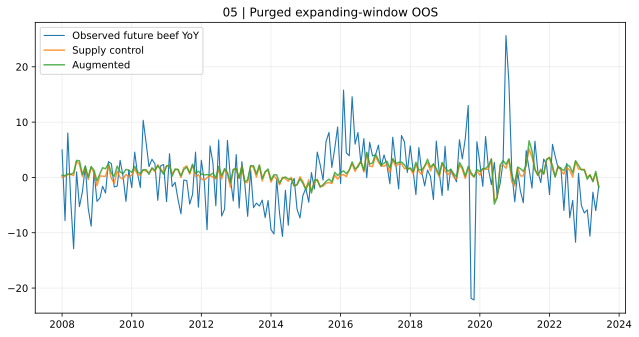

In [23]:
display(SVG(filename=str(FIGURES/'05_oos_predictions.svg')))

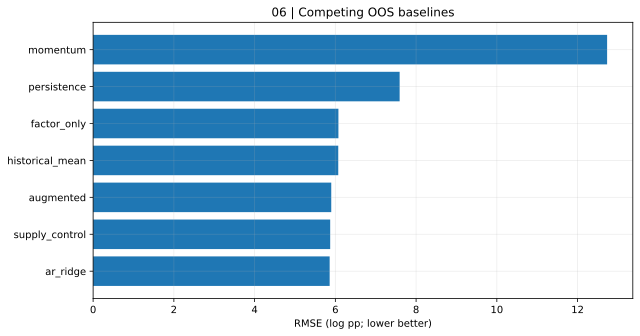

In [24]:
display(SVG(filename=str(FIGURES/'06_rmse_scorecard.svg')))

In [25]:
loss=(pred.target-pred.supply_control)**2-(pred.target-pred.augmented)**2
print('Paired squared loss: mean=',round(loss.mean(),5),'median=',round(loss.median(),5))
display(pd.DataFrame({'date':pred.date,'paired_sq_loss_gain':loss}).tail(10))

Paired squared loss: mean= -0.30915 median= -0.02083


,date,paired_sq_loss_gain
176,2022-09-01,-6.851991
177,2022-10-01,-5.243149
178,2022-11-01,-1.546781
179,2022-12-01,0.804346
180,2023-01-01,1.897031
181,2023-02-01,3.978009
182,2023-03-01,-1.504139
183,2023-04-01,0.626970
184,2023-05-01,-4.485341
185,2023-06-01,-0.026451


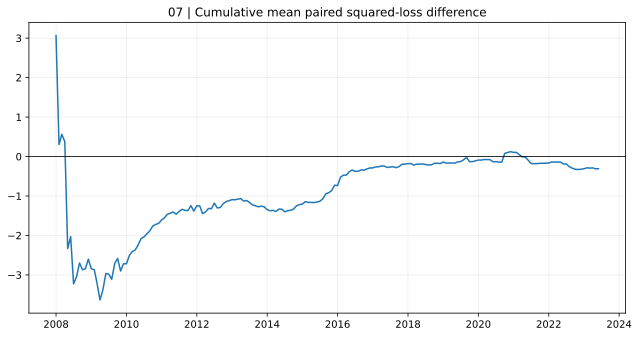

In [26]:
display(SVG(filename=str(FIGURES/'07_loss_gain.svg')))

## 10. Robustness & Placebos

**Exploratory 12-month-block factor reorder:** **1,000** full OOS refits with factor calendar blocks shuffled, preserving within-block structure. Upper-tail fraction for observed control-minus-augmented RMSE gain is **0.7522**; this is **not** an exact conditional permutation p-value because block reordering distorts long-run dependence and may alter correlations with controls.

**Paired circular-block bootstrap:** **2,000** 12-month-block resamples of the same 186 OOS forecast pairs; 95% gain interval **[-0.1152, +0.0631] log-pp**, spanning zero. **Weight perturbation:** **1,000** draws of broiler weight uniformly 0.1–0.9 (turkey = 1−w); **0.0%** beat the control. Component ablations:

| case                             |   n_oos |   gain_log_pp |
|:---------------------------------|--------:|--------------:|
| primary_70_30_poultry_minus_pork |     186 |       -0.0263 |
| broiler_only_minus_pork          |     186 |       -0.0099 |
| turkey_only_minus_pork           |     186 |       -0.0411 |
| poultry_only_no_pork             |     186 |       -0.0297 |
| negative_pork_only               |     186 |        0.0040 |
| linear_unbounded_factor          |     186 |       -0.0246 |

The **leave-one-OOS-year-out** test excludes each evaluation calendar year from score computation (16 years; no model refit) and retains a negative gain in **all 16 exclusions**. This is a stability diagnostic, not issuer leave-one-out. Company leave-one-out cannot be estimated from one firm and is explicitly **NOT TESTED**.

In [27]:
placebo=pd.read_csv(RESULTS/'placebo_draws.csv').gain_log_pp
boot=pd.read_csv(RESULTS/'bootstrap_draws.csv').gain_log_pp
print('Block-reorder draws:',len(placebo),'exploratory upper tail:',metrics['placebo_exploratory_tail_fraction'])
print('Bootstrap draws:',len(boot),'CI:',boot.quantile([.025,.975]).to_dict())

Block-reorder draws: 1000 exploratory upper tail: 0.7522477522477522
Bootstrap draws: 2000 CI: {0.025: -0.11520044919967211, 0.975: 0.06309037435239336}


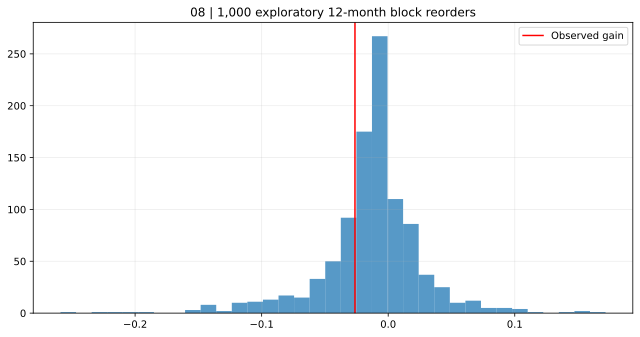

In [28]:
display(SVG(filename=str(FIGURES/'08_placebo.svg')))

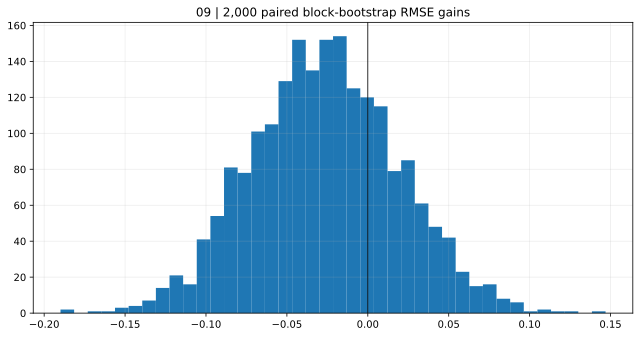

In [29]:
display(SVG(filename=str(FIGURES/'09_bootstrap.svg')))

In [30]:
weights=pd.read_csv(RESULTS/'weight_perturbations.csv')
print('Weight draws:',len(weights),'positive gain fraction:',(weights.gain_log_pp>0).mean())
display(weights.gain_log_pp.describe().to_frame())

Weight draws: 1000 positive gain fraction: 0.0


,gain_log_pp
count,1000.000000
mean,-0.031351
std,0.006643
min,-0.040077
25%,-0.036986
50%,-0.032684
75%,-0.026722
max,-0.016209


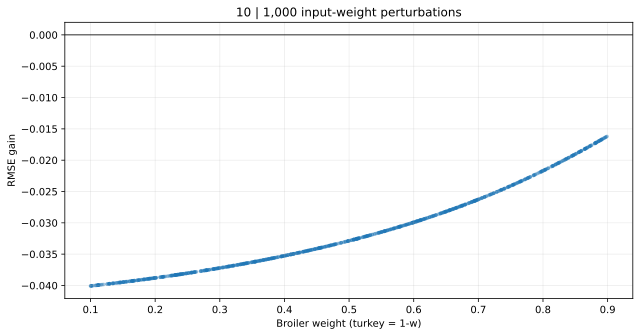

In [31]:
display(SVG(filename=str(FIGURES/'10_exposure_weights.svg')))

In [32]:
abl=pd.read_csv(RESULTS/'ablation_checks.csv')
display(abl.round(5))

,case,n_oos,gain_log_pp
0,primary_70_30_poultry_minus_pork,186,-0.02626
1,broiler_only_minus_pork,186,-0.00989
2,turkey_only_minus_pork,186,-0.04114
3,poultry_only_no_pork,186,-0.02972
4,negative_pork_only,186,0.00402
5,linear_unbounded_factor,186,-0.02458


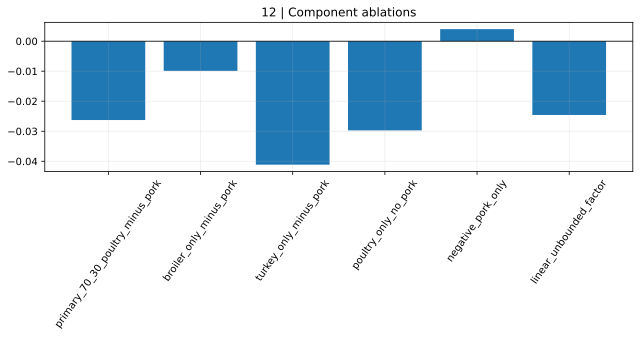

In [33]:
display(SVG(filename=str(FIGURES/'12_ablation.svg')))

## 11. Regime Sensitivity

**Fixed primary specification by OOS calendar regime:**

| regime    |   n |   control_rmse |   augmented_rmse |   gain_log_pp |
|:----------|----:|---------------:|-----------------:|--------------:|
| 2008-2014 |  84 |         5.1407 |           5.2578 |       -0.1171 |
| 2015-2019 |  60 |         6.3568 |           6.2422 |        0.1146 |
| 2020-2021 |  24 |         6.5600 |           6.6002 |       -0.0401 |
| 2022-2023 |  18 |         6.3983 |           6.5237 |       -0.1254 |

A positive gain in 2015–2019 is offset by negative gains in 2008–2014, 2020–2021 and 2022–2023. The full lag/horizon grid is **post-hoc** and must not be used to reselect a new primary result:

|   lag_months |   horizon_months |    n_oos |   control_rmse |   augmented_rmse |   gain_log_pp |
|-------------:|-----------------:|---------:|---------------:|-----------------:|--------------:|
|       1.0000 |           1.0000 | 191.0000 |         5.9698 |           5.9517 |        0.0181 |
|       1.0000 |           3.0000 | 189.0000 |         6.0377 |           6.0289 |        0.0088 |
|       1.0000 |           6.0000 | 186.0000 |         5.8513 |           5.9028 |       -0.0515 |
|       1.0000 |          12.0000 | 180.0000 |         6.0144 |           6.0818 |       -0.0674 |
|       2.0000 |           1.0000 | 191.0000 |         5.6292 |           5.6144 |        0.0148 |
|       2.0000 |           3.0000 | 189.0000 |         5.9626 |           5.9804 |       -0.0178 |
|       2.0000 |           6.0000 | 186.0000 |         5.8723 |           5.8986 |       -0.0263 |
|       2.0000 |          12.0000 | 180.0000 |         5.8509 |           5.8854 |       -0.0345 |
|       3.0000 |           1.0000 | 191.0000 |         6.0082 |           5.9994 |        0.0088 |
|       3.0000 |           3.0000 | 189.0000 |         5.7096 |           5.6986 |        0.0110 |
|       3.0000 |           6.0000 | 186.0000 |         5.6458 |           5.6479 |       -0.0022 |
|       3.0000 |          12.0000 | 180.0000 |         6.0126 |           6.1230 |       -0.1104 |
|       6.0000 |           1.0000 | 191.0000 |         5.8383 |           5.8862 |       -0.0479 |
|       6.0000 |           3.0000 | 189.0000 |         5.6422 |           5.6445 |       -0.0024 |
|       6.0000 |           6.0000 | 186.0000 |         6.0599 |           6.0664 |       -0.0066 |
|       6.0000 |          12.0000 | 180.0000 |         5.9065 |           5.9771 |       -0.0706 |

Overlapping six-month YoY targets create strong serial dependence; the paired 12-month block bootstrap is a sensitivity exercise, not a guarantee of valid asymptotic coverage under regime shifts. The 2022–2023 regime has only 18 OOS origins.

In [34]:
regime=pd.read_csv(RESULTS/'regime_checks.csv')
display(regime.round(4))

,regime,n,control_rmse,augmented_rmse,gain_log_pp
0,2008-2014,84,5.1407,5.2578,-0.1171
1,2015-2019,60,6.3568,6.2422,0.1146
2,2020-2021,24,6.5600,6.6002,-0.0401
3,2022-2023,18,6.3983,6.5237,-0.1254


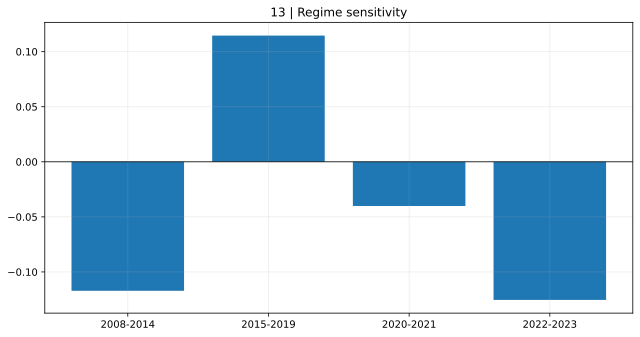

In [35]:
display(SVG(filename=str(FIGURES/'13_regime.svg')))

In [36]:
alt=pd.read_csv(RESULTS/'lag_horizon_checks.csv')
display(alt.pivot(index='lag_months',columns='horizon_months',values='gain_log_pp').round(4))

horizon_months,1,3,6,12
lag_months,,,,
1,0.0181,0.0088,-0.0515,-0.0674
2,0.0148,-0.0178,-0.0263,-0.0345
3,0.0088,0.0110,-0.0022,-0.1104
6,-0.0479,-0.0024,-0.0066,-0.0706


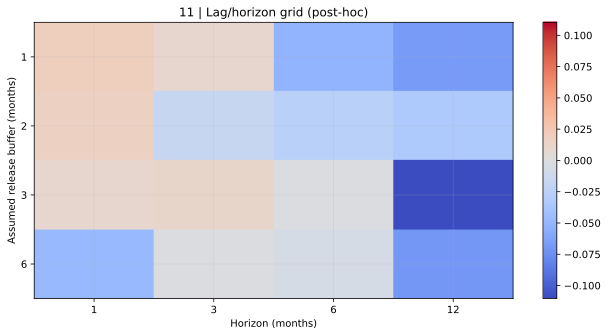

In [37]:
display(SVG(filename=str(FIGURES/'11_horizon_lag.svg')))

In [38]:
leave=pd.read_csv(RESULTS/'leave_one_year_out.csv')
print('Leave-one-OOS-year-out:',len(leave),'years; positive gain exclusions:',int((leave.gain_log_pp>0).sum()))
display(leave.round(5))

Leave-one-OOS-year-out: 16 years; positive gain exclusions: 0


,excluded_oos_year,n,gain_log_pp
0,2008,174,-0.01301
1,2009,174,-0.01117
2,2010,174,-0.02957
3,2011,174,-0.02510
4,2012,174,-0.02757
5,2013,174,-0.01596
6,2014,174,-0.02306
7,2015,174,-0.04357
8,2016,174,-0.04726
9,2017,174,-0.03135


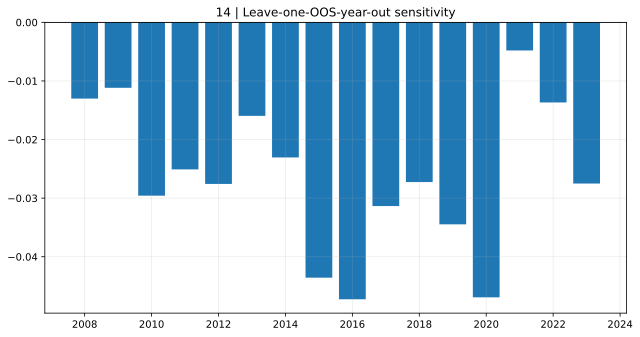

In [39]:
display(SVG(filename=str(FIGURES/'14_leave_year_out.svg')))

## 12. Bias Audit & Verdict

**Lookahead:** all features shifted by the assumed two-month buffer, training labels purged until target month + buffer, train-only preprocessing. **Unresolved:** historical revisions and exact first-publication vintages. **Selection:** industry and formula chosen after surveying repository topics; 70/30 weights and horizon were fixed before running the primary scorecard, but the study is not preregistered. **Multiple testing:** 16 lag/horizon combinations and ablations are descriptive, not family-wise-corrected discoveries. **Survivorship:** the national series has no security-universe selection, while the one-issuer SEC mapping is a surviving-company illustration and cannot validate equity effects. **Regimes:** pandemic, cattle-cycle and structural-break exposure. **Costs/capacity:** not computable without tradable return signals. **Issuer fundamentals:** three SEC fiscal-year rows, not a historical matched panel; company returns and benchmark-adjusted total returns absent.

**Verdict: negative retrospective beef-production macro-factor falsification.** Do not describe the factor as an investable alpha, a PIT backtest, or a reliable fundamental lead. The null is not rejected by the exploratory placebo and bootstrap uncertainty; the primary model worsens the benchmark.

In [40]:
audit=pd.DataFrame([
 ('lookahead','lag and target-release purge enforced','PASS conditional on assumed lag'),
 ('historical vintages','original release snapshots unavailable','FAIL PIT'),
 ('company fundamentals','one issuer, three fiscal years, SEC filed 2023-11-13','DESCRIPTIVE ONLY'),
 ('security returns','no adjusted total returns or delisted universe','NOT TESTED'),
 ('selection and multiplicity','16 post-hoc lag/horizon combinations','EXPLORATORY'),
 ('execution and costs','no investable portfolio','NOT APPLICABLE')],columns=['risk','evidence','status'])
display(audit)

,risk,evidence,status
0,lookahead,lag and target-release purge enforced,PASS conditional on assumed lag
1,historical vintages,original release snapshots unavailable,FAIL PIT
2,company fundamentals,"one issuer, three fiscal years, SEC filed 2023...",DESCRIPTIVE ONLY
3,security returns,no adjusted total returns or delisted universe,NOT TESTED
4,selection and multiplicity,16 post-hoc lag/horizon combinations,EXPLORATORY
5,execution and costs,no investable portfolio,NOT APPLICABLE


In [41]:
assert metrics['observed_rmse_gain_log_pp']<0
assert metrics['bootstrap_gain_ci_95'][0]<0<metrics['bootstrap_gain_ci_95'][1]
print('VERDICT: NEGATIVE RETROSPECTIVE BEEF-PRODUCTION MACRO FALSIFICATION; NOT PIT; NOT EQUITY ALPHA')

VERDICT: NEGATIVE RETROSPECTIVE BEEF-PRODUCTION MACRO FALSIFICATION; NOT PIT; NOT EQUITY ALPHA


## 13. Reproduction

From this study directory, with Python 3.11+ and dependencies installed, run:

```bash
python -m pip install -r requirements.txt
python -m pytest -q tests
python run_analysis.py
jupyter nbconvert --to notebook --execute research.ipynb --output executed_research.ipynb
```

`run_analysis.py` writes a frozen formation panel, OOS forecast table, baseline scorecard, 1,000 placebo draws, 2,000 bootstrap draws, 1,000 exposure perturbations, lag/horizon and ablation tables, 16 leave-one-year-out scores, regime checks, summary JSON and **15 computed SVG diagnostics**. The committed notebook contains executed code outputs and SVG images; `logs/` includes actual analysis/test/notebook execution records. The fast cumulative sufficient-statistics Ridge routine is unit-tested against the slow fold-by-fold implementation. For the repository-wide structure check, run `python scripts/validate_studies.py` from repository root. GitHub Actions structural CI is a separate gate, not numerical/PIT validation.

In [42]:
artifacts=sorted([str(f.relative_to(HERE)) for folder in ['data','results','figures']
 for f in (HERE/folder).glob('*') if f.is_file()])
print('Computed/frozen artifacts:',len(artifacts))
print('\n'.join(artifacts))

Computed/frozen artifacts: 30
data/company_exposure_map.csv
data/derived_formation_panel.csv
data/raw_plotnine_meat_2023_snapshot.csv
data/source_register.csv
data/tyson_fy2023_sec_fundamentals.csv
figures/01_red_meat_output.svg
figures/02_poultry_output.svg
figures/03_factor_history.svg
figures/04_scatter.svg
figures/05_oos_predictions.svg
figures/06_rmse_scorecard.svg
figures/07_loss_gain.svg
figures/08_placebo.svg
figures/09_bootstrap.svg
figures/10_exposure_weights.svg
figures/11_horizon_lag.svg
figures/12_ablation.svg
figures/13_regime.svg
figures/14_leave_year_out.svg
figures/15_tyson_fundamentals.svg
results/ablation_checks.csv
results/baseline_scorecard.csv
results/bootstrap_draws.csv
results/lag_horizon_checks.csv
results/leave_one_year_out.csv
results/oos_predictions.csv
results/placebo_draws.csv
results/regime_checks.csv
results/summary.json
results/weight_perturbations.csv


In [43]:
print('Notebook execution uses run_all() with actual 1,000/2,000/1,000 draws.')
print('Repository structural CI is separate from numerical and historical-PIT validation.')

Notebook execution uses run_all() with actual 1,000/2,000/1,000 draws.
Repository structural CI is separate from numerical and historical-PIT validation.


## 14. Next-Stage Protocol

1. Acquire dated USDA NASS *Livestock Slaughter* first-release PDFs/CSVs and monthly ERS historical revisions; build an observation-level `(observation_month, first_release_timestamp, revision_vintage, value)` panel. Freeze retrieval hashes and compare the plotnine file to the corresponding official monthly values.
2. Add cattle-on-feed placements, slaughter counts, feed prices, cold-storage inventory, boxed-beef spreads, imports/exports, plant utilization and weekly retail price series. Predefine mechanistic lags before a fresh holdout and test substitution versus common-demand explanations.
3. Build a multi-issuer, historical-universe SEC segment dataset with actual 10-K/10-Q filing timestamps and consistent fiscal quarters; test sales and margins separately from physical output, with issuer exclusions and revision-aware alignment.
4. Only after successful fundamental evidence, obtain delisting-inclusive, dividend/split-adjusted security total returns, benchmark and factor exposures, execution timing, borrow and costs. Pre-register a clean future holdout, report multiple-testing adjustments and decline an alpha claim if net OOS gains fail.

In [44]:
next_steps=['Acquire archived USDA first-release vintages and audit revisions',
 'Add cattle-on-feed, feed prices, cold storage and export volumes',
 'Build dated multi-issuer SEC fundamentals and filing availability',
 'Only then test delisting-inclusive total returns and costs']
display(pd.DataFrame({'stage':range(1,5),'required_data_or_test':next_steps}))

,stage,required_data_or_test
0,1,Acquire archived USDA first-release vintages a...
1,2,"Add cattle-on-feed, feed prices, cold storage ..."
2,3,Build dated multi-issuer SEC fundamentals and ...
3,4,Only then test delisting-inclusive total retur...


## 15. Sources & Artifacts

**Primary references:** [plotnine frozen-source documentation](https://plotnine.org/reference/meat.html) (Grade B numerical redistribution; assembly date UNKNOWN); [USDA ERS production documentation](https://www.ers.usda.gov/data-products/livestock-and-meat-domestic-data/documentation) (Grade A definitions; page date UNKNOWN); [USDA ERS Livestock and Meat Domestic Data](https://www.ers.usda.gov/data-products/livestock-and-meat-domestic-data) (Grade A current source, updated 2026-10-27; NOT the numerical vintage); [Tyson FY2023 SEC 10-K](https://www.sec.gov/Archives/edgar/data/100493/000010049323000105/tsn-20230930.htm) (Grade A, filed 2023-11-13; segment fundamentals only). Exact observation periods, revision/vintage caveats and roles are in `data/source_register.csv`.

**Artifacts:** `data/raw_plotnine_meat_2023_snapshot.csv`, `data/derived_formation_panel.csv`, `data/tyson_fy2023_sec_fundamentals.csv`, `data/company_exposure_map.csv`, `results/*.csv`, `results/summary.json`, `figures/*.svg`, `research.ipynb`, `run_analysis.py`, `tests/test_analysis.py`, `requirements.txt`, `study.json`, `logs/`. Source grades describe provenance and do **not** certify point-in-time numerical integrity.

In [45]:
display(sources[['id','grade','exact_url','release_date','vintage','limitation']])

,id,grade,exact_url,release_date,vintage,limitation
0,S01,B,https://plotnine.org/reference/meat.html,UNKNOWN (bundled snapshot not dated),local frozen redistributed CSV SHA256 b587c1e7...,Not independently reconciled to official histo...
1,S02,A,https://www.ers.usda.gov/data-products/livesto...,UNKNOWN (documentation undated),Current documentation not source snapshot,No proof of frozen file's historical availability
2,S03,A,https://www.ers.usda.gov/data-products/livesto...,2026-10-27 (page updated),Current page not used as numerical input,Does not establish 1960-2023 first-release tim...
3,S04,A,https://www.sec.gov/Archives/edgar/data/100493...,2023-11-13,2023 SEC filing; NOT PIT for pre-filing origins,Three fiscal-year observations do not permit c...


In [46]:
summary=json.loads((RESULTS/'summary.json').read_text())
print(json.dumps({k:summary[k] for k in ['oos_n','observed_rmse_gain_log_pp',
 'placebo_exploratory_tail_fraction','bootstrap_gain_ci_95','pit_verified',
 'equity_alpha_established','status']},indent=2))

{
  "oos_n": 186,
  "observed_rmse_gain_log_pp": -0.02626379920255495,
  "placebo_exploratory_tail_fraction": 0.7522477522477522,
  "bootstrap_gain_ci_95": [
    -0.11520044919967218,
    0.0630903743523934
  ],
  "pit_verified": false,
  "equity_alpha_established": false,
  "status": "REPRODUCED RETROSPECTIVE BEEF PROCESSING MACRO PILOT - NOT PIT / NOT EQUITY ALPHA"
}
